<a href="https://colab.research.google.com/github/NiloferMubeen/Brain-Tumour-detection/blob/main/Fish_image_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Library imports

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix

# Device check

In [ ]:
tf.config.list_physical_devices('GPU')

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

# Mount drive

In [ ]:
import os
import zipfile
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


# File Extraction

In [ ]:
# 2. Specify paths
drive_path = '/content/drive/MyDrive'  # Adjust if your file is in a different folder
zip_file_path = os.path.join(drive_path, 'Dataset.zip')  # Change to your zip file name
extract_path = '/content/dataset'  # Where to extract files

# 3. Create extraction directory if it doesn't exist
os.makedirs(extract_path, exist_ok=True)

# 4. Extract the zip file
with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)
    print(f"Extracted files to: {extract_path}")

# 5. Verify the extracted folders
dataset_path = os.path.join(extract_path, 'extract')  # Change to your extracted folder name
train_dir = os.path.join(dataset_path, '/content/dataset/images.cv_jzk6llhf18tm3k0kyttxz/data/train')
val_dir = os.path.join(dataset_path, '/content/dataset/images.cv_jzk6llhf18tm3k0kyttxz/data/val')
test_dir = os.path.join(dataset_path, '/content/dataset/images.cv_jzk6llhf18tm3k0kyttxz/data/test')

print("\nVerifying directories:")
print("Train exists:", os.path.exists(train_dir))
print("Validation exists:", os.path.exists(val_dir))
print("Test exists:", os.path.exists(test_dir))

# 6. Sample directory listing (optional)
if os.path.exists(train_dir):
    print("\nSample train directory contents:")
    print(os.listdir(train_dir)[:5])  # Show first 5 items

Extracted files to: /content/dataset

Verifying directories:
Train exists: True
Validation exists: True
Test exists: True

Sample train directory contents:
['fish sea_food hourse_mackerel', 'fish sea_food shrimp', 'fish sea_food striped_red_mullet', 'fish sea_food sea_bass', 'animal fish']


# Data Preprocessing and Augmentation

In [ ]:
# Training data generator with augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,  # Normalize pixel values to [0, 1]

    # Data augmentation parameters
    rotation_range=20,  # Random rotation between -20 and +20 degrees
    width_shift_range=0.2,  # Random horizontal shift by ±20% of width
    height_shift_range=0.2,  # Random vertical shift by ±20% of height
    zoom_range=0.2,  # Random zoom between 80% and 120%
    horizontal_flip=True,  # Random horizontal flipping
    vertical_flip=False,  # No vertical flipping (can enable if appropriate)
    fill_mode='nearest'  # Strategy for filling in newly created pixels
)

# Validation and test generators (only rescaling, no augmentation)
val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

In [ ]:
# Set image size and batch size
img_width, img_height = 224, 224  # Adjust as needed
batch_size = 32  # Adjust as needed

# Create data generators
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(img_width, img_height),
    batch_size=batch_size,
    class_mode='categorical'  # or 'binary' if you have two classes
)

validation_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=(img_width, img_height),
    batch_size=batch_size,
    class_mode='categorical'
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(img_width, img_height),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False  # Important for evaluating the test set
)

Found 6225 images belonging to 11 classes.
Found 1092 images belonging to 11 classes.
Found 3187 images belonging to 11 classes.


# Get class names and number of classes



In [ ]:
class_names = list(train_generator.class_indices.keys())
num_classes = len(class_names)
print(f"Class names: {class_names}")
print(f"Number of classes: {num_classes}")

Class names: ['animal fish', 'animal fish bass', 'fish sea_food black_sea_sprat', 'fish sea_food gilt_head_bream', 'fish sea_food hourse_mackerel', 'fish sea_food red_mullet', 'fish sea_food red_sea_bream', 'fish sea_food sea_bass', 'fish sea_food shrimp', 'fish sea_food striped_red_mullet', 'fish sea_food trout']
Number of classes: 11


# Build a simple CNN model

In [ ]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(img_height, img_width, 3)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


# Compile the model

In [ ]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy',
                       tf.keras.metrics.Precision(name='precision'),
                       tf.keras.metrics.Recall(name='recall')])

# Model summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 11)             │         1,419 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,170,379 (42.61 MB)

 Trainable params: 11,170,379 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

# Train the model

In [ ]:
epochs = 15
history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // batch_size,
    epochs=epochs,
    validation_data=validation_generator,
    validation_steps=validation_generator.samples // batch_size
)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15
194/194 ━━━━━━━━━━━━━━━━━━━━ 94s 442ms/step - accuracy: 0.2935 - loss: 1.9736 - precision: 0.6690 - recall: 0.1072 - val_accuracy: 0.5616 - val_loss: 1.1789 - val_precision: 0.8227 - val_recall: 0.3796
Epoch 2/15
  1/194 ━━━━━━━━━━━━━━━━━━━━ 9s 50ms/step - accuracy: 0.5625 - loss: 1.3053 - precision: 0.7500 - recall: 0.2812

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/epoch_iterator.py:107: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.5625 - loss: 1.3053 - precision: 0.7500 - recall: 0.2812 - val_accuracy: 0.6590 - val_loss: 0.9974 - val_precision: 0.8623 - val_recall: 0.4375
Epoch 3/15
194/194 ━━━━━━━━━━━━━━━━━━━━ 81s 416ms/step - accuracy: 0.6187 - loss: 1.0460 - precision: 0.7668 - recall: 0.4588 - val_accuracy: 0.7693 - val_loss: 0.7015 - val_precision: 0.8428 - val_recall: 0.6700
Epoch 4/15
194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.7188 - loss: 0.6444 - precision: 0.8000 - recall: 0.6250 - val_accuracy: 0.7665 - val_loss: 0.6909 - val_precision: 0.8483 - val_recall: 0.6682
Epoch 5/15
194/194 ━━━━━━━━━━━━━━━━━━━━ 82s 424ms/step - accuracy: 0.7304 - loss: 0.7438 - precision: 0.8158 - recall: 0.6267 - val_accuracy: 0.8364 - val_loss: 0.4984 - val_precision: 0.8909 - val_recall: 0.7656
Epoch 6/15
194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9062 - loss: 0.4663 - precision: 0.9167 - recall: 0.6875 - val_accuracy: 0.7077 - val_loss: 0.8237

# Plot training history

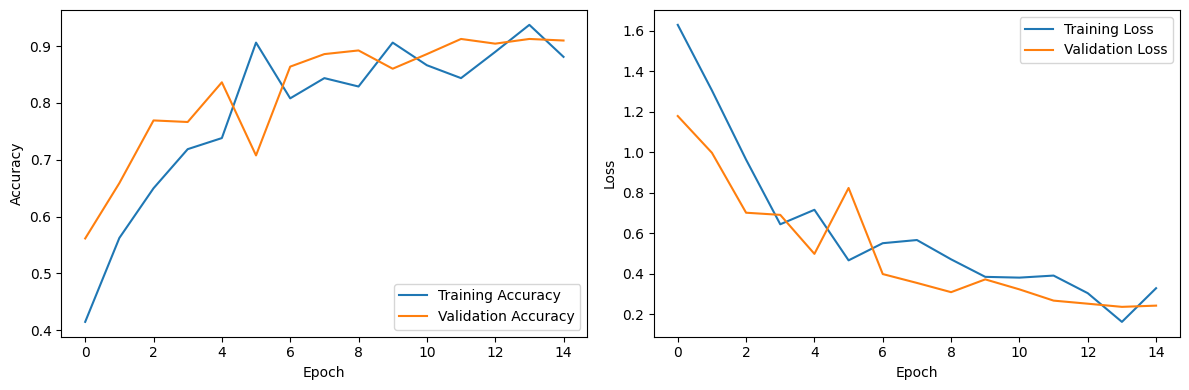

In [ ]:
def plot_history(history):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_history(history)

# Evaluate on test set

In [ ]:
test_loss, test_acc, test_precision, test_recall = model.evaluate(test_generator)
print(f'\nTest accuracy: {test_acc:.4f}')
print(f'Test precision: {test_precision:.4f}')
print(f'Test recall: {test_recall:.4f}')

100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 69ms/step - accuracy: 0.9304 - loss: 0.2235 - precision: 0.9470 - recall: 0.9192

Test accuracy: 0.9209
Test precision: 0.9392
Test recall: 0.9065


# Generate predictions

In [ ]:
test_generator.reset()
predictions = model.predict(test_generator, steps=test_generator.samples // batch_size + 1)
predicted_classes = np.argmax(predictions, axis=1)

100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 53ms/step


# Get true classes

In [ ]:
true_classes = test_generator.classes

# Classification report

In [ ]:
print('\nClassification Report:')
print(classification_report(true_classes, predicted_classes, target_names=class_names))

# Confusion matrix
conf_mat = confusion_matrix(true_classes, predicted_classes)
print('\nConfusion Matrix:')
print(conf_mat)


Classification Report:
                                  precision    recall  f1-score   support

                     animal fish       0.98      0.99      0.98       520
                animal fish bass       0.00      0.00      0.00        13
   fish sea_food black_sea_sprat       0.98      1.00      0.99       298
   fish sea_food gilt_head_bream       0.97      0.64      0.77       305
   fish sea_food hourse_mackerel       0.91      0.96      0.93       286
        fish sea_food red_mullet       0.91      1.00      0.95       291
     fish sea_food red_sea_bream       0.90      0.87      0.88       273
          fish sea_food sea_bass       0.71      0.89      0.79       327
            fish sea_food shrimp       0.99      1.00      0.99       289
fish sea_food striped_red_mullet       0.98      0.89      0.93       293
             fish sea_food trout       0.95      0.98      0.96       292

                        accuracy                           0.92      3187
            

#Setup and Data Preparation

In [ ]:
import os
import pandas as pd
import tensorflow as tf
from tensorflow.keras.applications import (VGG16, ResNet50, MobileNet,
                                          InceptionV3, EfficientNetB0)
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

dataset_path = os.path.join(extract_path, 'extract')

train_dir = os.path.join(dataset_path, '/content/dataset/images.cv_jzk6llhf18tm3k0kyttxz/data/train')
val_dir = os.path.join(dataset_path, '/content/dataset/images.cv_jzk6llhf18tm3k0kyttxz/data/val')
test_dir = os.path.join(dataset_path, '/content/dataset/images.cv_jzk6llhf18tm3k0kyttxz/data/test')


# Data generators setup
img_size = (224, 224)
batch_size = 32

train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    horizontal_flip=True
)
val_datagen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical'
)
val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical'
)

num_classes = len(train_generator.class_indices)
class_names = list(train_generator.class_indices.keys())

# Results storage
model_comparison = []

Found 6225 images belonging to 11 classes.
Found 1092 images belonging to 11 classes.


# VGG16 Evaluation

In [ ]:
def evaluate_vgg16():
    base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base_model.trainable = False

    model = tf.keras.Sequential([
        base_model,
        GlobalAveragePooling2D(),
        Dropout(0.2),
        Dense(num_classes, activation='softmax')
    ])

    model.compile(optimizer=Adam(0.001),
                 loss='categorical_crossentropy',
                 metrics=['accuracy',
                         tf.keras.metrics.Precision(name='precision'),
                         tf.keras.metrics.Recall(name='recall')])

    history = model.fit(
        train_generator,
        validation_data=val_generator,
        epochs=10,
        callbacks=[EarlyStopping(patience=3)]
    )

    return model, history

vgg_model, vgg_history = evaluate_vgg16()
model_comparison.append({
    'Model': 'VGG16',
    'Val Accuracy': max(vgg_history.history['val_accuracy']),
    'Val Precision': max(vgg_history.history['val_precision']),
    'Val Recall': max(vgg_history.history['val_recall']),
    'Parameters': f"{vgg_model.count_params():,}",
    'Inference Time': 'Medium',
    'Best For': 'Medium-sized datasets'
})

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 129s 568ms/step - accuracy: 0.2293 - loss: 2.2065 - precision: 0.7943 - recall: 0.0195 - val_accuracy: 0.6447 - val_loss: 1.6962 - val_precision: 0.9468 - val_recall: 0.0815
Epoch 2/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 93s 474ms/step - accuracy: 0.5598 - loss: 1.6396 - precision: 0.9748 - recall: 0.1006 - val_accuracy: 0.6859 - val_loss: 1.3897 - val_precision: 0.9419 - val_recall: 0.1337
Epoch 3/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 100s 511ms/step - accuracy: 0.6750 - loss: 1.3651 - precision: 0.9723 - recall: 0.1449 - val_accuracy: 0.7418 - val_loss: 1.1862 - val_precision: 0.9576 - val_recall: 0.2070
Epoch 4/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 117s 602ms/step - accuracy: 0.7101 - loss: 1.1936 - precision: 0.9781 - recall: 0.2157 - val_accuracy: 0.7793 - val_loss: 1.0545 - val_precision: 0.9673 - val_recall: 0.2711
Epoch 5/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 123s 630ms/step - accuracy: 0.7608 - loss: 1.0700 - precision: 0.9703 - recall: 0.2775 - val_accuracy: 0.

# Plot training history

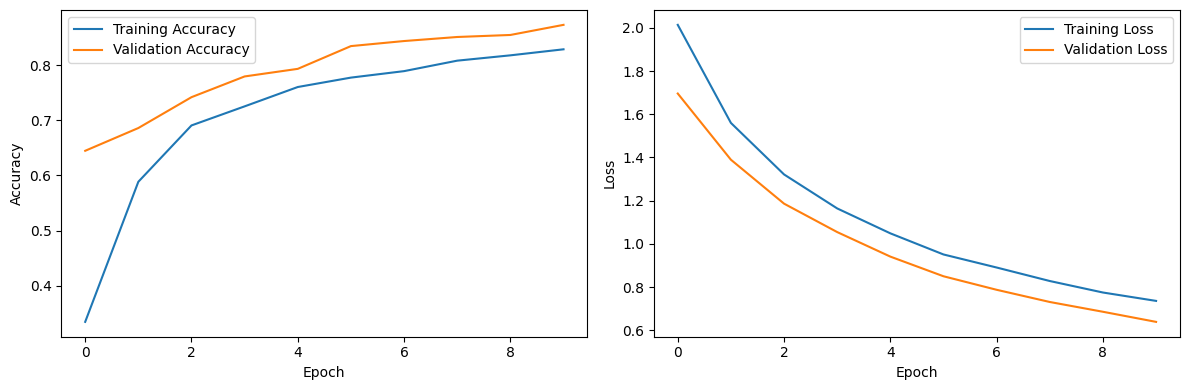

100/100 ━━━━━━━━━━━━━━━━━━━━ 30s 298ms/step - accuracy: 0.9215 - loss: 0.4694 - precision: 0.9795 - recall: 0.7567

Test accuracy: 0.8848
Test precision: 0.9770
Test recall: 0.6668
100/100 ━━━━━━━━━━━━━━━━━━━━ 21s 197ms/step


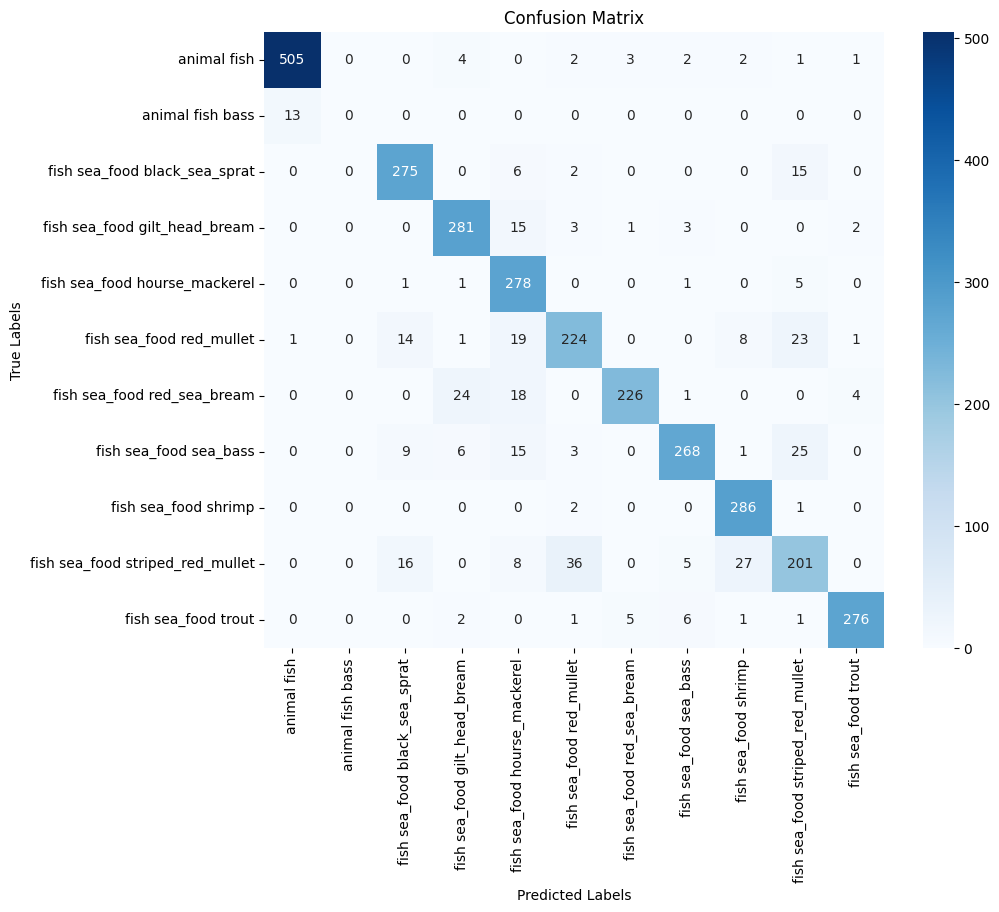

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix


def plot_history(history):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_history(vgg_history)


# Evaluate on test set (assuming you have a test_generator)
test_generator.reset() # Reset the generator before evaluating
test_loss, test_acc, test_precision, test_recall = vgg_model.evaluate(test_generator)
print(f'\nTest accuracy: {test_acc:.4f}')
print(f'Test precision: {test_precision:.4f}')
print(f'Test recall: {test_recall:.4f}')


# Generate predictions
predictions = vgg_model.predict(test_generator)
predicted_classes = np.argmax(predictions, axis=1)

# Get true classes
true_classes = test_generator.classes

# Confusion Matrix
conf_mat = confusion_matrix(true_classes, predicted_classes)

# Plot confusion matrix using seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

# ResNet50 Evaluation

In [ ]:
def evaluate_resnet50():
    base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base_model.trainable = False

    inputs = tf.keras.Input(shape=(224, 224, 3))
    x = tf.keras.applications.resnet50.preprocess_input(inputs)
    x = base_model(x, training=False)
    x = GlobalAveragePooling2D()(x)
    x = Dropout(0.2)(x)
    outputs = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs, outputs)
    model.compile(optimizer=Adam(0.001),
                 loss='categorical_crossentropy',
                 metrics=['accuracy', 'precision', 'recall'])

    history = model.fit(
        train_generator,
        validation_data=val_generator,
        epochs=10,
        callbacks=[EarlyStopping(patience=3)]
    )

    return model, history

resnet_model, resnet_history = evaluate_resnet50()
model_comparison.append({
    'Model': 'ResNet50',
    'Val Accuracy': max(resnet_history.history['val_accuracy']),
    'Val Precision': max(resnet_history.history['val_precision']),
    'Val Recall': max(resnet_history.history['val_recall']),
    'Parameters': f"{resnet_model.count_params():,}",
    'Inference Time': 'Medium',
    'Best For': 'General purpose'
})

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 109s 485ms/step - accuracy: 0.1318 - loss: 2.4601 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.2005 - val_loss: 2.2509 - val_precision: 1.0000 - val_recall: 9.1575e-04
Epoch 2/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 80s 408ms/step - accuracy: 0.1850 - loss: 2.2553 - precision: 0.0306 - recall: 4.9604e-06 - val_accuracy: 0.2189 - val_loss: 2.1815 - val_precision: 1.0000 - val_recall: 0.0018
Epoch 3/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 79s 406ms/step - accuracy: 0.2091 - loss: 2.1997 - precision: 0.8811 - recall: 0.0028 - val_accuracy: 0.2189 - val_loss: 2.1271 - val_precision: 1.0000 - val_recall: 0.0046
Epoch 4/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 80s 410ms/step - accuracy: 0.2163 - loss: 2.1645 - precision: 0.7994 - recall: 0.0043 - val_accuracy: 0.2253 - val_loss: 2.1244 - val_precision: 1.0000 - val_recall: 0.0165
Epoch 5/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 83s 425ms/step - accuracy: 0.2256 - loss

# MobileNet Evaluation

In [ ]:
def evaluate_mobilenet():
    base_model = MobileNet(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base_model.trainable = False

    model = tf.keras.Sequential([
        base_model,
        GlobalAveragePooling2D(),
        Dropout(0.2),
        Dense(num_classes, activation='softmax')
    ])

    model.compile(optimizer=Adam(0.001),
                 loss='categorical_crossentropy',
                 metrics=['accuracy', 'precision', 'recall'])

    history = model.fit(
        train_generator,
        validation_data=val_generator,
        epochs=10,
        callbacks=[EarlyStopping(patience=3)]
    )

    return model, history

mobilenet_model, mobilenet_history = evaluate_mobilenet()
model_comparison.append({
    'Model': 'MobileNet',
    'Val Accuracy': max(mobilenet_history.history['val_accuracy']),
    'Val Precision': max(mobilenet_history.history['val_precision']),
    'Val Recall': max(mobilenet_history.history['val_recall']),
    'Parameters': f"{mobilenet_model.count_params():,}",
    'Inference Time': 'Fast',
    'Best For': 'Mobile/Edge devices'
})

17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 89s 423ms/step - accuracy: 0.5748 - loss: 1.3650 - precision: 0.7971 - recall: 0.4126 - val_accuracy: 0.9515 - val_loss: 0.2298 - val_precision: 0.9679 - val_recall: 0.9112
Epoch 2/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 131s 389ms/step - accuracy: 0.9358 - loss: 0.2438 - precision: 0.9561 - recall: 0.9001 - val_accuracy: 0.9744 - val_loss: 0.1107 - val_precision: 0.9805 - val_recall: 0.9661
Epoch 3/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 75s 385ms/step - accuracy: 0.9707 - loss: 0.1350 - precision: 0.9775 - recall: 0.9575 - val_accuracy: 0.9835 - val_loss: 0.0703 - val_precision: 0.9853 - val_recall: 0.9789
Epoch 4/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 75s 383ms/step - accuracy: 0.9788 - loss: 0.0915 - precision: 0.9851 - recall: 0.9681 - val_accuracy: 0.9918 - val_loss: 0.0494 - val_precision: 0.9917 - val_recall: 0.9872
Epoch 5/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 76s 391ms/step - accuracy: 0.9857 - loss: 0.0742 - preci

# Plot training history for MobileNet

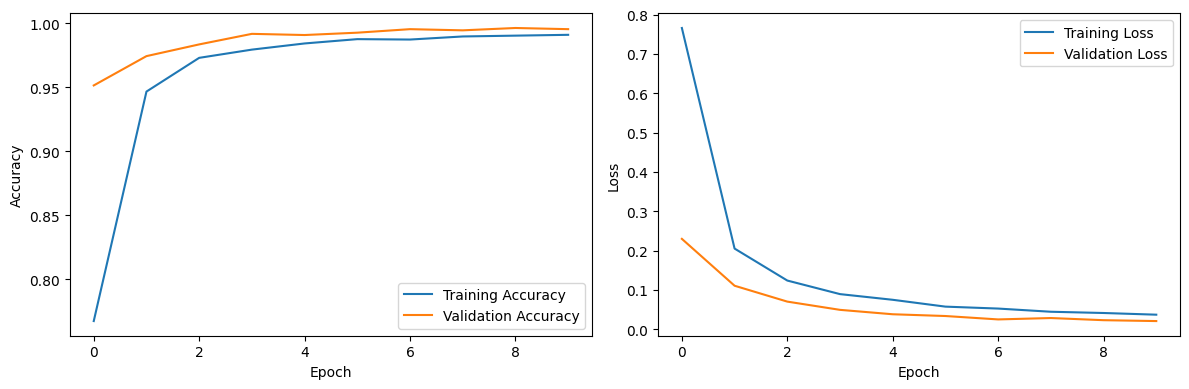

In [ ]:
plot_history(mobilenet_history)

# Evaluate on test set for MobileNet

100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 84ms/step - accuracy: 0.9952 - loss: 0.0179 - precision: 0.9954 - recall: 0.9952

MobileNet Test accuracy: 0.9947
MobileNet Test precision: 0.9956
MobileNet Test recall: 0.9947
100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 66ms/step


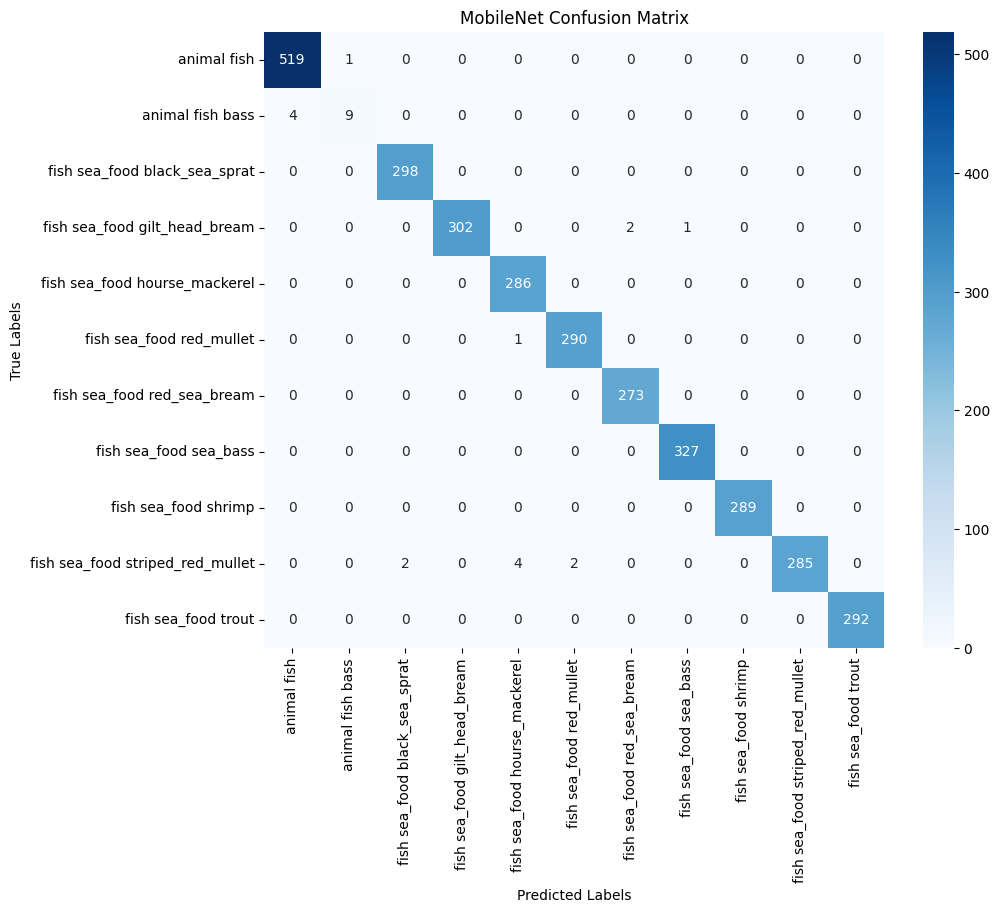

In [ ]:
test_generator.reset()  # Reset the generator before evaluating
test_loss, test_acc, test_precision, test_recall = mobilenet_model.evaluate(test_generator)
print(f'\nMobileNet Test accuracy: {test_acc:.4f}')
print(f'MobileNet Test precision: {test_precision:.4f}')
print(f'MobileNet Test recall: {test_recall:.4f}')

# Generate predictions for MobileNet
predictions = mobilenet_model.predict(test_generator)
predicted_classes = np.argmax(predictions, axis=1)

# Get true classes for MobileNet
true_classes = test_generator.classes

# Confusion Matrix for MobileNet
conf_mat = confusion_matrix(true_classes, predicted_classes)

# Plot confusion matrix for MobileNet using seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('MobileNet Confusion Matrix')
plt.show()

# InceptionV3 Evaluation

In [ ]:
def evaluate_inception():
    # Special generator for Inception's 299x299 input
    inception_train_gen = train_datagen.flow_from_directory(
        train_dir, target_size=(299, 299), batch_size=batch_size)
    inception_val_gen = val_datagen.flow_from_directory(
        val_dir, target_size=(299, 299), batch_size=batch_size)

    base_model = InceptionV3(weights='imagenet', include_top=False, input_shape=(299, 299, 3))
    base_model.trainable = False

    inputs = tf.keras.Input(shape=(299, 299, 3))
    x = tf.keras.applications.inception_v3.preprocess_input(inputs)
    x = base_model(x, training=False)
    x = GlobalAveragePooling2D()(x)
    x = Dropout(0.2)(x)
    outputs = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs, outputs)
    model.compile(optimizer=Adam(0.001),
                 loss='categorical_crossentropy',
                 metrics=['accuracy', 'precision', 'recall'])

    history = model.fit(
        inception_train_gen,
        validation_data=inception_val_gen,
        epochs=10,
        callbacks=[EarlyStopping(patience=3)]
    )

    return model, history

inception_model, inception_history = evaluate_inception()
model_comparison.append({
    'Model': 'InceptionV3',
    'Val Accuracy': max(inception_history.history['val_accuracy']),
    'Val Precision': max(inception_history.history['val_precision']),
    'Val Recall': max(inception_history.history['val_recall']),
    'Parameters': f"{inception_model.count_params():,}",
    'Inference Time': 'Medium',
    'Best For': 'Multi-scale features'
})


Found 6225 images belonging to 11 classes.
Found 1092 images belonging to 11 classes.
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 191s 838ms/step - accuracy: 0.1681 - loss: 2.2919 - precision: 0.4209 - recall: 9.8564e-04 - val_accuracy: 0.2381 - val_loss: 2.0701 - val_precision: 1.0000 - val_recall: 0.0192
Epoch 2/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 138s 707ms/step - accuracy: 0.2409 - loss: 2.1056 - precision: 0.9413 - recall: 0.0280 - val_accuracy: 0.2912 - val_loss: 1.9910 - val_precision: 0.9730 - val_recall: 0.0659
Epoch 3/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 136s 697ms/step - accuracy: 0.2708 - loss: 2.0364 - precision: 0.9415 - recall: 0.0419 - val_accuracy: 0.3269 - val_loss: 1.8932 - val_precision: 0.9630 - val_recall: 0.0714
Epoch 4/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 133s 681ms/step - accuracy: 0.3109 - loss: 1.9513 - precision: 0.9503 - recall: 0.0615 - val_accuracy: 0.3755 - val_loss: 1.8429 - val_precision: 0.9744 - val_recall: 0.0696
Epoch 5/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 137s 702ms/step - accuracy: 0.3153 - loss: 1.9090 - precision: 0.9082 - recall: 0.0734 - val_accurac

# EfficientNetB0 Evaluation

In [ ]:
def evaluate_efficientnet():
    base_model = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base_model.trainable = False

    model = tf.keras.Sequential([
        base_model,
        GlobalAveragePooling2D(),
        Dropout(0.2),
        Dense(num_classes, activation='softmax')
    ])

    model.compile(optimizer=Adam(0.001),
                 loss='categorical_crossentropy',
                 metrics=['accuracy', 'precision', 'recall'])

    history = model.fit(
        train_generator,
        validation_data=val_generator,
        epochs=10,
        callbacks=[EarlyStopping(patience=3)]
    )

    return model, history

efficientnet_model, efficientnet_history = evaluate_efficientnet()
model_comparison.append({
    'Model': 'EfficientNetB0',
    'Val Accuracy': max(efficientnet_history.history['val_accuracy']),
    'Val Precision': max(efficientnet_history.history['val_precision']),
    'Val Recall': max(efficientnet_history.history['val_recall']),
    'Parameters': f"{efficientnet_model.count_params():,}",
    'Inference Time': 'Fast',
    'Best For': 'Best accuracy/efficiency tradeoff'
})

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 149s 550ms/step - accuracy: 0.1603 - loss: 2.3480 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.1712 - val_loss: 2.3224 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 82s 423ms/step - accuracy: 0.1668 - loss: 2.3096 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.1712 - val_loss: 2.3275 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 139s 406ms/step - accuracy: 0.1678 - loss: 2.3212 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.1712 - val_loss: 2.3337 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 4/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 80s 411ms/step - accuracy: 0.1703 - loss: 2.3185 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.0943 - val_loss: 2.3445 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00


# Results Comparison

In [ ]:
comparison_df = pd.DataFrame(model_comparison)
comparison_df = comparison_df.sort_values('Val Accuracy', ascending=False)
comparison_df.style.background_gradient(cmap='Blues', subset=['Val Accuracy', 'Val Precision', 'Val Recall'])

,Model,Val Accuracy,Val Precision,Val Recall,Parameters,Inference Time,Best For
2,MobileNet,0.996337,0.997248,0.995421,"3,240,139",Fast,Mobile/Edge devices
0,VGG16,0.872711,0.967320,0.643773,"14,720,331",Medium,Medium-sized datasets
3,InceptionV3,0.456960,1.000000,0.106227,"21,825,323",Medium,Multi-scale features
1,ResNet50,0.323260,1.000000,0.044872,"23,610,251",Medium,General purpose
4,EfficientNetB0,0.171245,0.000000,0.000000,"4,063,662",Fast,Best accuracy/efficiency tradeoff


# Save the DataFrame to a CSV file

In [ ]:
comparison_df.to_csv('/content/drive/MyDrive/model_comparison.csv', index=False)

In [ ]:
import pandas as pd
df=pd.read_csv('/content/drive/MyDrive/model_comparison.csv')
df

,Model,Val Accuracy,Val Precision,Val Recall,Parameters,Inference Time,Best For
0,MobileNet,0.996337,0.997248,0.995421,"3,240,139",Fast,Mobile/Edge devices
1,VGG16,0.872711,0.967320,0.643773,"14,720,331",Medium,Medium-sized datasets
2,InceptionV3,0.456960,1.000000,0.106227,"21,825,323",Medium,Multi-scale features
3,ResNet50,0.323260,1.000000,0.044872,"23,610,251",Medium,General purpose
4,EfficientNetB0,0.171245,0.000000,0.000000,"4,063,662",Fast,Best accuracy/efficiency tradeoff


# Find the best model

The best performing model is:
Model                       MobileNet
Val Accuracy                 0.996337
Val Precision                0.997248
Val Recall                   0.995421
Parameters                  3,240,139
Inference Time                   Fast
Best For          Mobile/Edge devices
Name: 0, dtype: object


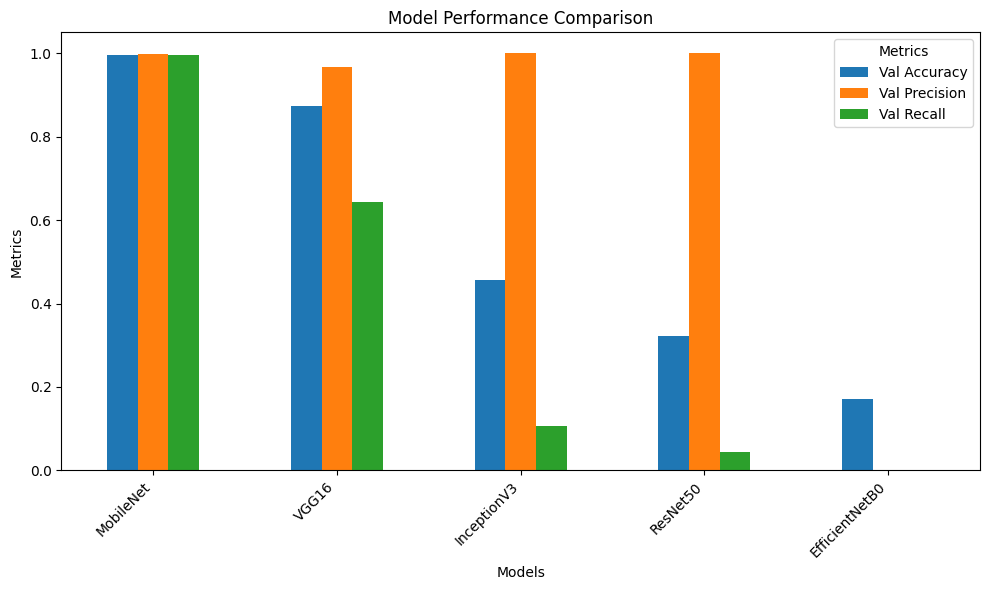

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('/content/drive/MyDrive/model_comparison.csv')


# Find the best model based on validation accuracy
best_model = df.loc[df['Val Accuracy'].idxmax()]

print(f"The best performing model is:\n{best_model}")

# Plotting the bar chart
plt.figure(figsize=(10, 6))
df.plot(x='Model', y=['Val Accuracy', 'Val Precision', 'Val Recall'], kind='bar', ax=plt.gca())
plt.title('Model Performance Comparison')
plt.ylabel('Metrics')
plt.xlabel('Models')


plt.xticks(rotation=45, ha='right')
plt.legend(title='Metrics')
plt.tight_layout()
plt.show()

# Save the model

In [ ]:
mobilenet_model.save('/content/drive/MyDrive/mobilenet_model.h5')

# Create the Streamlit app for custom fish classification

# Install required packages

In [ ]:
!pip install streamlit numpy pillow tensorflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 71.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 122.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 7.7 MB/s eta 0:00:00


In [ ]:
%%writefile custom_fish_classifier.py

import streamlit as st
import numpy as np
from PIL import Image
import tensorflow as tf
from tensorflow.keras.preprocessing.image import img_to_array
from tensorflow.keras.models import load_model
import os


FISH_CLASSES=['animal fish', 'animal fish bass', 'fish sea_food black_sea_sprat', 'fish sea_food gilt_head_bream', 'fish sea_food hourse_mackerel', 'fish sea_food red_mullet', 'fish sea_food red_sea_bream', 'fish sea_food sea_bass', 'fish sea_food shrimp', 'fish sea_food striped_red_mullet', 'fish sea_food trout']


# Load stom trained model
@st.cache_resource
def load_custom_model():
    model_path = '/content/drive/MyDrive/mobilenet_model.h5'
    if not os.path.exists(model_path):
        st.error(f"Model file not found at {model_path}")
        return None
    return load_model(model_path)

model = load_custom_model()

# Streamlit app
st.title("🎣 Custom Fish Species Classifier")
st.write(f"Upload a fish image to classify")

# File uploader
uploaded_file = st.file_uploader("Choose a fish image...",
                                type=["jpg", "jpeg", "png"])

if uploaded_file is not None and model is not None:
    # Display the uploaded image
    image = Image.open(uploaded_file)
    st.image(image, caption='Uploaded Image', use_column_width=True)

    # Preprocess the image
    image = image.resize((224, 224))  # Match your model's expected input
    image_array = img_to_array(image)
    image_array = image_array / 255.0  # Normalize (if your model expects this)
    image_array = np.expand_dims(image_array, axis=0)

    # Make prediction
    with st.spinner('Identifying fish species...'):
        predictions = model.predict(image_array)
        predicted_class = FISH_CLASSES[np.argmax(predictions)]
        confidence = np.max(predictions)

    # Display results
    st.subheader("Prediction Results:")
    st.success(f"Species: {predicted_class}")
    st.info(f"Confidence: {confidence*100:.2f}%")

    # Show all class probabilities
    st.subheader("All Class Probabilities:")
    for i, (cls, prob) in enumerate(zip(FISH_CLASSES, predictions[0])):
        st.write(f"{cls}: {prob*100:.2f}%")
        st.progress(float(prob))


Writing custom_fish_classifier.py


In [ ]:
!wget -q -O - ipv4.icanhazip.com

34.75.68.160


In [ ]:
! streamlit run custom_fish_classifier.py & npx localtunnel --port 8501



⠙⠹⠸⠼⠴⠦⠧⠇
  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.75.68.160:8501

your url is: https://young-insects-hang.loca.lt
2025-06-09 07:38:13.442732: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1749454693.482320   47175 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1749454693.497862   47175 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-06-09 07:38:18.438874: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config val